## our goal is doing the **Bivariate Analysis** on our smartphone data so we can driven on to the conclusion on the specs and smartphone prices and brands.

## I have decided two main columns that more important in this Analysis columns are (price & rating).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
plt.rcParams['figure.figsize']=(16,8)

In [3]:
df=pd.read_csv('/content/EDA_Univariate_Analysis_done.csv')

In [4]:
pd.set_option('display.max_column',None)

In [5]:
plt.style.use('bmh')

In [6]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

## Brand with Price

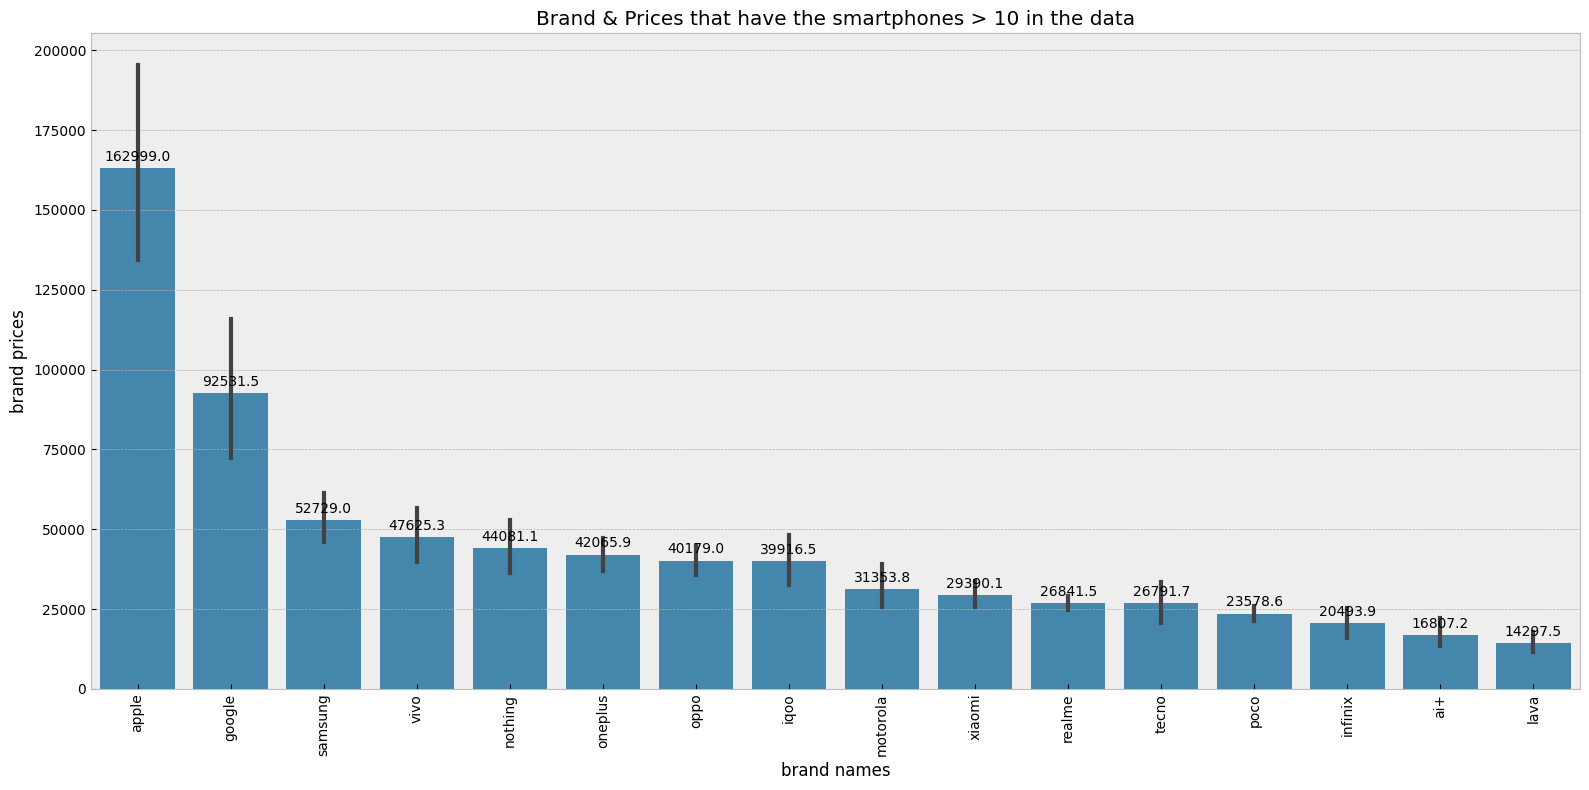

In [7]:

brand_counts = df['brand_name'].value_counts()
valid_brands = brand_counts[brand_counts > 10].index
filtered_df = df[df['brand_name'].isin(valid_brands)]


sorted_order = (
    filtered_df.groupby('brand_name')['price'].mean().sort_values(ascending=False).index
)


plt.figure(figsize=(16, 8))
ax = sns.barplot(data=filtered_df, x='brand_name', y='price', order=sorted_order)

for container in ax.containers:
  ax.bar_label(container, fmt='%.1f', padding=3)

plt.title('Brand & Prices that have the smartphones > 10 in the data')
plt.xlabel('brand names')
plt.ylabel('brand prices')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


- I plot this column together because i want to see the which brand have the highest Avg price with the minimum count in the data so here are smartphones brand that have the atleast 10 or more smartphone in the data.

- Here are 16 brands have atleast or more 10 counts.

- As in the above bar plot the data shows the **apple** is the highest avg prices with its mobiles means its Avg smartphones is sold around **1,62,999**
because of the recennt apple smartphone the **iPhone duo** is about **4,49,900** thats why the apples bar is higher than the others.

- and then **google** in that list as the Avg price is **92581.5** its normal that the google avg range is that much as there smartphones are comes under slightly premium side.

## Brand with specs

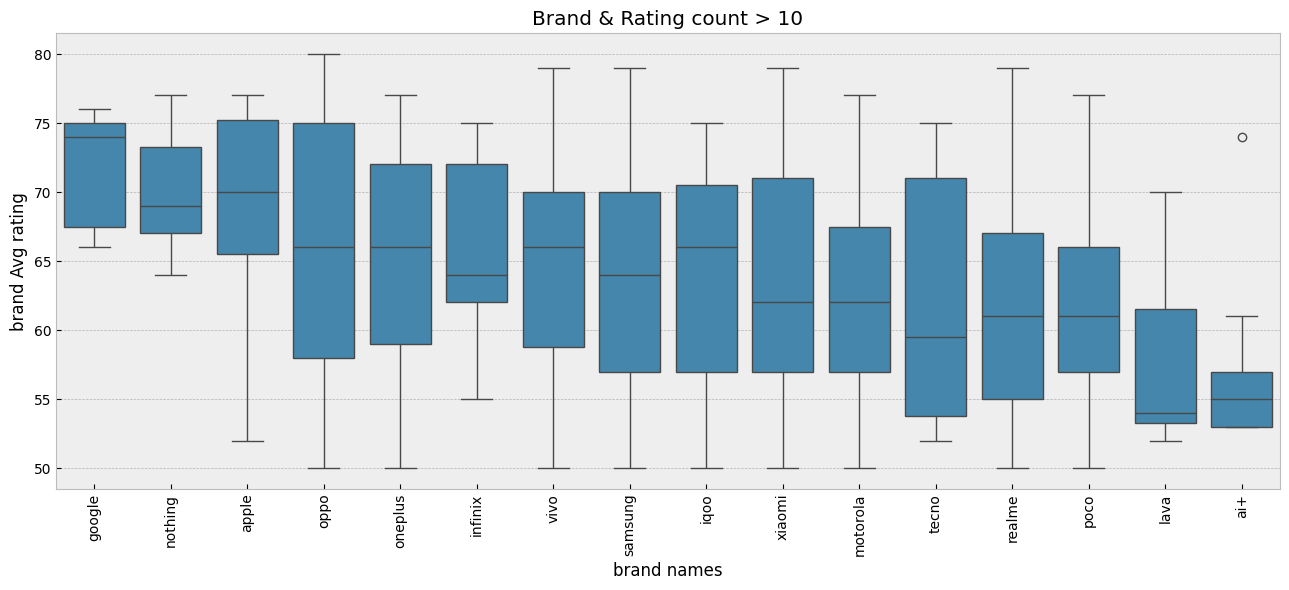

In [8]:
sorted_array=(filtered_df.groupby('brand_name').rating.mean().sort_values(ascending=False).index
)

plt.figure(figsize=(13,6))

ax=sns.boxplot(data=filtered_df,x='brand_name',y='rating',order=sorted_array)


plt.title('Brand & Rating count > 10')
plt.xlabel('brand names')
plt.ylabel('brand Avg rating')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

- I done this plot because of i want to see which brand have the how much Rating as their brand value and Advertising offer us.

## Brand Name and has_5g

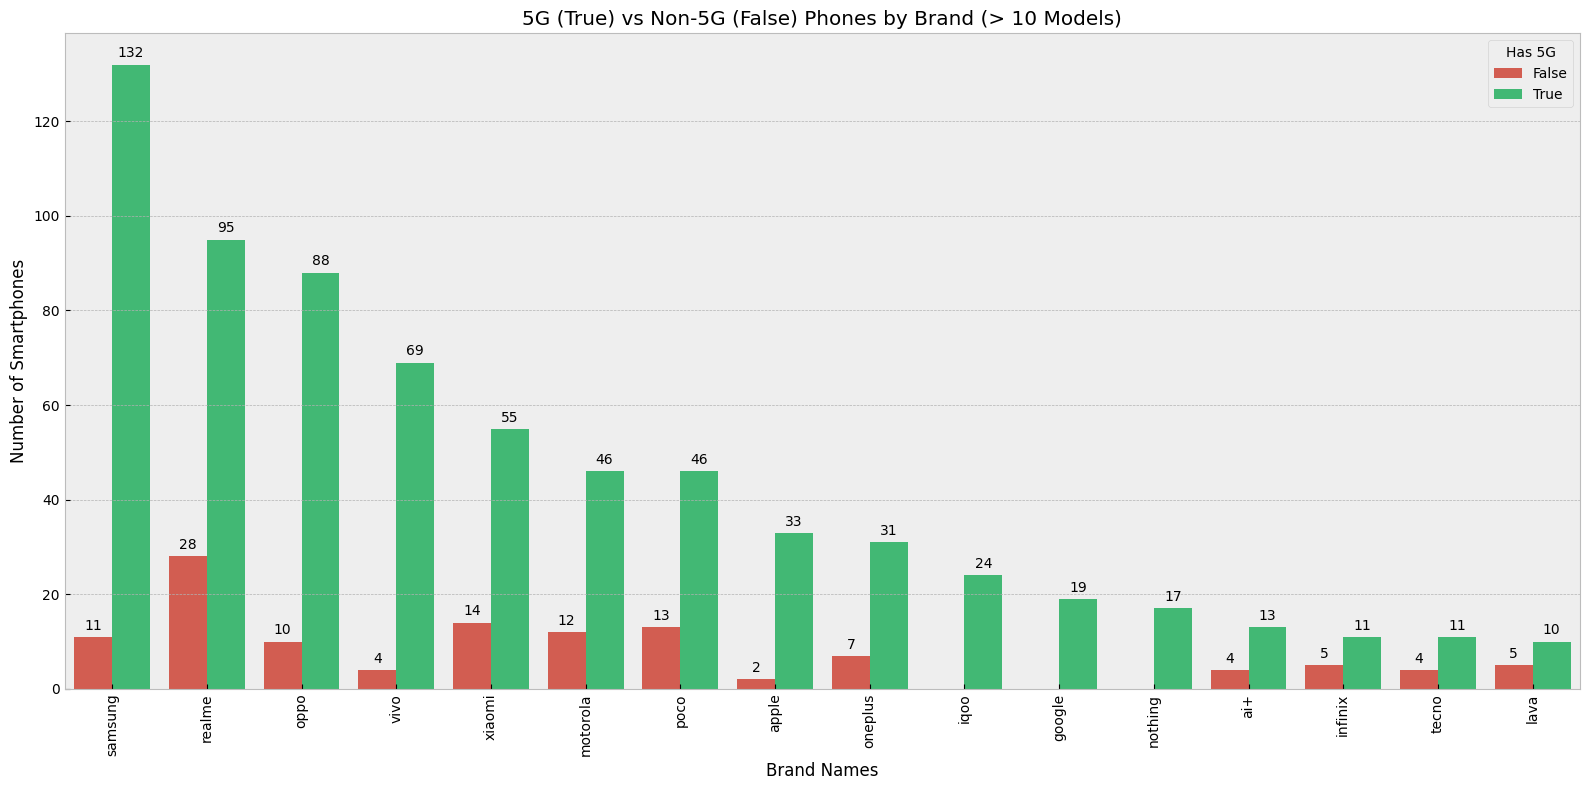

In [9]:
sorted_order = (
    filtered_df.groupby('brand_name')['has_5g']
    .sum()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(16, 8))
ax = sns.countplot(
    data=filtered_df,
    x='brand_name',
    hue='has_5g',
    order=sorted_order,
    palette={True: '#2ecc71', False: '#e74c3c'},
)

for container in ax.containers:
  ax.bar_label(container, padding=3)

plt.title('5G (True) vs Non-5G (False) Phones by Brand (> 10 Models)')
plt.xlabel('Brand Names')
plt.ylabel('Number of Smartphones')
plt.legend(title='Has 5G')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


- I plot this Graph i want to check which brand have the 5g phones as internet technology changing


## brand_name with has_nfc

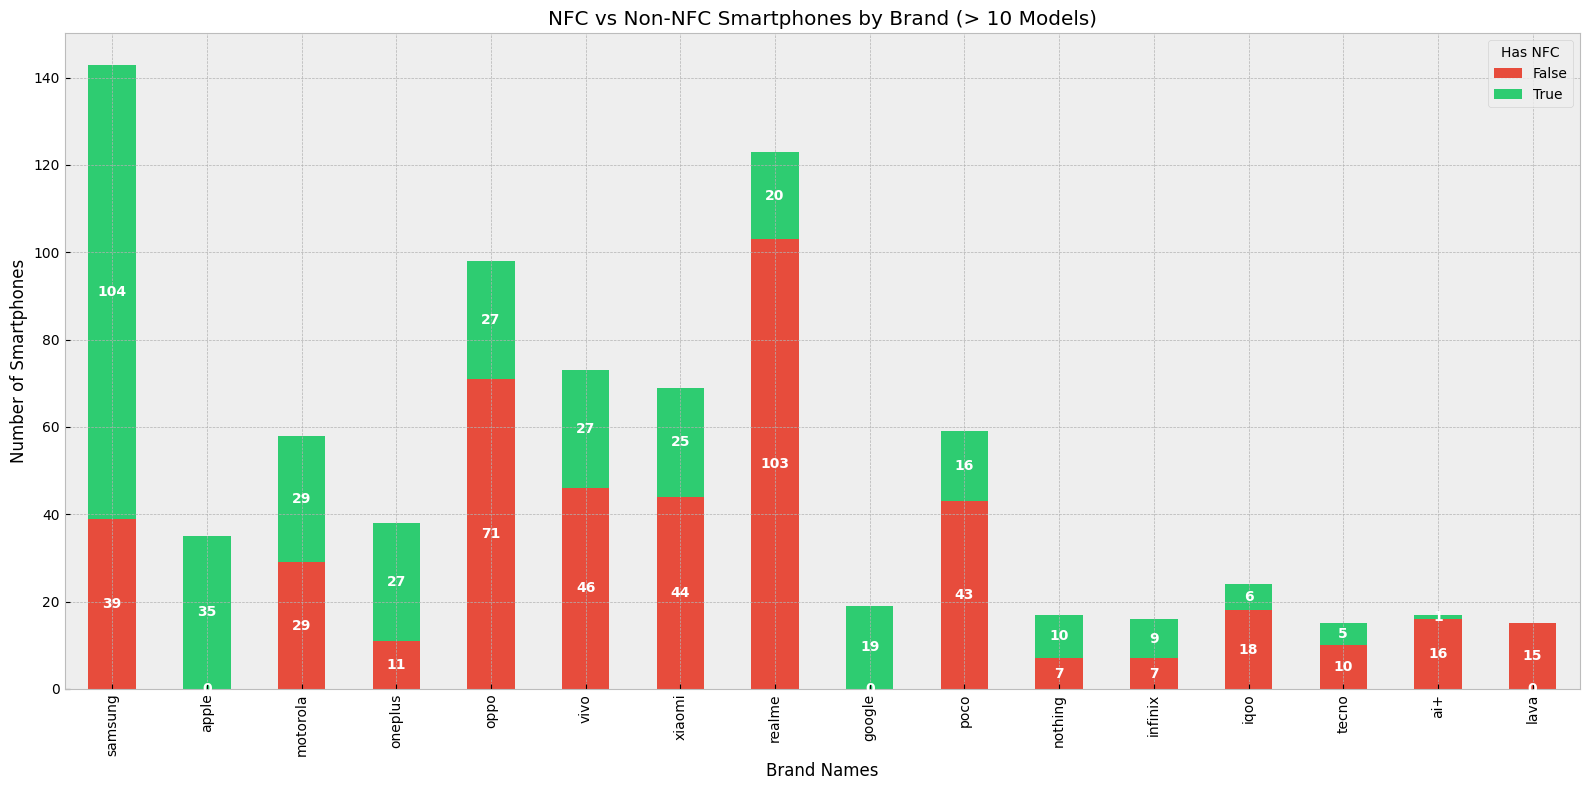

In [10]:
ct = pd.crosstab(filtered_df['brand_name'], filtered_df['has_nfc'])
ct = ct.loc[ct[True].sort_values(ascending=False).index]

ax = ct.plot(kind='bar', stacked=True, figsize=(16, 8), color=['#e74c3c', '#2ecc71'])

for container in ax.containers:
  ax.bar_label(container, label_type='center', color='white', fontweight='bold')

plt.title('NFC vs Non-NFC Smartphones by Brand (> 10 Models)')
plt.xlabel('Brand Names')
plt.ylabel('Number of Smartphones')
plt.legend(title='Has NFC')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


## price vs rating

In [11]:
import plotly.express as px

fig = px.scatter(
    filtered_df,
    x='price',
    y='rating',
    range_x=[0,240000],
    hover_data=['brand_name','name'],
    title='Price vs Rating',
    width=1200,
    height=600,
)

fig.update_xaxes(dtick=20000, tickformat=',')
fig.show()


- In this we cannot say that like a **price range** that have the best rating.

- beackause in the graph the data shows the lower end mobiles have also the 70 to 75 rating that high price mobiles dont have

- And some high price range smartphones have the 75 to 8o ratiung so we cannot say that this price rang is best or cheap mobiles not the best in the specs or Expensive mobiles have the best specs on the basis on the price.

## price vs has_5g

In [12]:
fig = px.box(
    filtered_df,
    x='has_5g',
    y='price',
    color='has_5g',
    points='outliers',
    hover_data=['brand_name','name'],
    title='Smartphone Price Distribution: 5G vs Non-5G',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=20000, tickformat=',')
fig.show()

- This plot is clearly telling us that 4G phones are coming lower than 5G as customers and internet is changing towards the 5G companies also reducing the smartphones that has 4g only.

- As in the true side the outliers are more but that is normal because the smartphone prices are higher and iphone duo is having outlier is normal.

- But 5G smartphones prices are also higher than the not having.

- As the 4G whisker plot have the lower_fence = 6,499 and upper_fence 24,999

## rating vs has_5G

In [13]:
fig = px.box(
    filtered_df,
    x='has_5g',
    y='rating',
    color='has_5g',
    points='outliers',
    hover_data=['brand_name','name'],
    range_y=[48, 82],
    title='Smartphone Rating Distribution: 5G vs Non-5G',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()

- 5G smartphones consistantly scores the higher rating than the not having 5G smartphones with zero outliers it showing us that 5G smartphones have the strong baseline of modern specs.

- AS the technology changed than the past years the customers also wan the good speed for the internet and if smartphone companies also pair the 5G with the good hardware and technologies then 5G smartphones earns more points in the smartprix spec-score formula.

## price with has_ir_blaster

In [14]:
fig = px.box(
    filtered_df,
    x='has_ir_blaster',
    y='price',
    color='has_ir_blaster',
    points='outliers',
    hover_data=['brand_name','name'],
    title='Smartphone Price Distribution: ir_blaster vs Non_having_ir_blaster',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=20000,tickformat=',')
fig.show()

- IR Blaster is a chinese technology that used to on the some home appliences like TV and more AC etc.

- so that is provided by mostly the chinese smartphone companies As in the outliers dots vivo is the most expensive in that and that chinese company.

- Having the ir blaster there is no that much impact in price. The smartphones that not havinbg IR Blaster have higher price than the IR Blaster phones.  

## Rating with IR Blaster

In [15]:
fig = px.box(
    filtered_df,
    x='has_ir_blaster',
    y='rating',
    color='has_ir_blaster',
    points='outliers',
    hover_data=['brand_name'],
    range_y=[48, 82],
    title='Smartphone Rating Distribution: Has IR Blaster vs No IR Blaster',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()


- Rating also not having that much diffrence in both false have slightlty greater rating than True.

## price with has_nfc

In [16]:
fig = px.box(
    filtered_df,
    x='has_nfc',
    y='price',
    color='has_nfc',
    log_y=True,
    points='outliers',
    hover_data=['brand_name'],
    title='Smartphone Price Distribution: Has NFC vs No NFC (Log Scale)',
    width=1000,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000,250000,300000,400000,450000],
    tickformat=',',
)
fig.show()


- So as NFC(Near Field Communication) is used to communicate the wireless devices together used for payment options.

- Having the NFC the price is higher that dosent mean the if smartphone have NFC then thats price is higher no some lower end phones have the NFC also. Yes but the median of both having the drastic diffrence as not having NFC mean is **22,223** and the True box plot having the mean of **48,990** as you can see the AVG price is twice of the false.

- Its happened because of recently launched apples iphone duo may be the reason of this diffrence.

- And all apple devices have the NFC so that twice is because of this smartphones.

## rating with has_nfc

In [17]:
fig = px.box(
    filtered_df,
    x='has_nfc',
    y='rating',
    color='has_nfc',
    points='outliers',
    hover_data=['brand_name'],
    range_y=[48, 82],
    title='Smartphone Rating Distribution: Has NFC vs No NFC',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()


- This chart is very intresting as the phones that have NFC the AVG rating is also 67 which is higher than the False and Min rating also slightly more than the False.

- But There is catch the one phone out of it having the Higher rating in the data set without having the NFC in it. That means if any phone that have the good hardware and more good features that can beat the upperend smartphones in specs.


In [18]:
filtered_df[(filtered_df['has_nfc'] == False) & (filtered_df['rating'] == 80)]

,name,brand_name,price,rating,has_5g,has_ir_blaster,has_nfc,has_foldable,num_cores,processor_speed,ram_capacity,internal_memory,processor_brand,fast_cahrging_available,battery_capacity,fast_charging,refresh_rate,extended_memory_available,extended_upto,screen_size,res_width,res_height,os,num_rear_cameras,num_front_cameras,primary_camera_rear,primary_camera_front
0,OPPO F35 Pro,oppo,34483.0,80.0,False,False,False,False,8,2.5,8,256.0,dimensity,1,8000.0,80.0,144.0,0,NaN,6.78,1272.0,2772.0,android,1,1,50.0,50.0


## price with has_foldable

In [19]:
fig = px.box(
    filtered_df,
    x='has_foldable',
    y='price',
    color='has_foldable',
    points='all',
    hover_data=['brand_name','name'],
    title='Smartphone Price Distribution: Foldable vs Non-Foldable',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=20000, tickformat=',')
fig.show()


- has_fldable can give the big impact on the price as in the plot the false AVG price is **29,787** and in other side the True has the median of **173,999** That creates the too much diffrence in the price

- This plots clears the image about the smartphone if the smartphone is foldable or have the dual display then thats price is so much high than the normal smartphone.

## rating with has_foldable

## price with num_cores

In [20]:
fig = px.box(
    filtered_df,
    x='num_cores',
    y='price',
    color='num_cores',
    points='all',
    log_y=True,
    hover_data=['brand_name','name'],
    category_orders={'num_cores': sorted(filtered_df['num_cores'].dropna().unique())},
    title='Smartphone Price Distribution by Number of Processor Cores (Log Scale)',
    width=1000,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 75000, 100000, 150000, 200000,250000,300000,350000,400000,450000],
    tickformat=',',
)

fig.update_xaxes(
    tickvals=[6,8,9,10]
)

fig.show()


- In data smartphones that have the 6 core(Hexa-Core) is from apple and as the smartphone is from apple there price is higher side.

- In Data the 8 core(Octa-Core) is in the from low range to mid range smartphones and as there is some 8 core smartphones but there price are too much high like (samung galaxy z fold)  is having the high price and thats why its the outlier.

- All 9 core(nona-Core) is actualy only in the Google smartphones and that have the mid range price.

- And last one is 10 Core(Deca-Core) are in the mid to high range and mostly having the samsung smartphones.

## Rating with num_cores

In [21]:
fig = px.box(
    filtered_df,
    x='num_cores',
    y='rating',
    color='num_cores',
    points='all',
    hover_data=['brand_name','name','price'],
    range_y=[48, 82],
    category_orders={
        'num_cores': sorted(filtered_df['num_cores'].dropna().unique())
    },
    title='Smartphone Rating Distribution by Number of Processor Cores',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.update_xaxes(
    tickvals=[6,8,9,10]
)
fig.show()


- As in the price the 6 cores smartphones have the most highest figures but in the rating it drop to the lower.

- As the 8 core is having the mostly smartphones contain this core but that dosent mean that the rating also low some smart phone have the high rating as compare to the higher price smartphones.


In [22]:
def plot(choice,col,title,log=False):
  if choice=='price':
          fig=px.box(
              filtered_df,
              x=col,
              y='price',
              color=col,
              points='all',
              hover_data=['brand_name','name'],
              title=title,
              height=600,
              width=1000
          )

          fig.update_yaxes(dtick=20000)

          fig.show()
  elif choice == 'rating':
          fig=px.box(
              filtered_df,
              x=col,
              y='rating',
              color=col,
              points='all',
              hover_data=['brand_name','name'],
              range_y=[48,82],
              title=title,
              height=600,
              width=1000
          )

          fig.update_yaxes(dtick=5)

          fig.show()

## processor_brand

In [23]:
plot('price',filtered_df.processor_brand,'Smartphone Rating Distribution by Processor Brand')

In [24]:
plot('price',filtered_df.processor_brand,'Smartphone Rating Distribution by Processor Brand',True)

- As in the price as we know the apple's processor bionic is having uphold in the price that shows apples bionic chips are go in the higherend smartphones.

- next surprising i saw in this the google smartphone the decent price with the median of the 94k and lowest is google pixel 6A so its come under the high range smartphone.

- Snapdragon is as it is in the mostly smartkphones thats why its median is 34k but the some smartphone that have this chip their price is so much higher than the normal range mostly smartphones are in less price so we consider it midrange chip here.

- Dimensity is also in the mid range chip just one smartphone is too mcuh expensive mostly chinese smartphone companies have this processor.

- helio and unisoc are the lower end chips that starts from the 6k to the 21k.

- As the other having the only one smartphone so as for the model it does not useful so we can remove it as it is not useful that much.

In [25]:
plot('rating',filtered_df.processor_brand,'Smartphone Rating Distribution by Processor Brand')

- The surprising fact is the bionic smartphones are less spec rating as compare to the google tensor processor chip.

- In the dimensity and the snapmdragon the spec rating also similar but the AVG rating of the snapdragon is higher than the dimensity but in the dimensity one smartphone crossing the 79 mark as the some processor brand have the smartphone that have the 79 rating but the one phone is having the 80 spec score rating.

- As all ways the exynos is the samsung's processor brand the Avg rating is 64.

- And the surprising box is the helio and the unisoc they are in the price having same but the unisoc is having the slightly better rating than the helio processor brand.

## ram_capacity

In [26]:
ram_order = sorted(filtered_df['ram_capacity'].dropna().unique())

fig = px.box(
    filtered_df,
    x='ram_capacity',
    y='price',
    color='ram_capacity',
    log_y=True,
    points='all',
    hover_data=['name', 'brand_name'],
    category_orders={'ram_capacity': ram_order},
    title='Smartphone Price Distribution by RAM Capacity (Log Scale)',
    width=1100,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000,300000,4000000],
    tickformat=',',
)

fig.update_xaxes(
              tickvals=[2,3,4,6,8,10,12,16]
          )

fig.show()

In [27]:
fig = px.box(
    filtered_df,
    x='ram_capacity',
    y='rating',
    color='ram_capacity',
    points='all',
    hover_data=['name', 'brand_name'],
    range_y=[48, 82],
    category_orders={'ram_capacity': ram_order},
    title='Smartphone Rating Distribution by RAM Capacity',
    width=1100,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()

- As the current scenario of ram prices it is normal that ram has big impact on the price and thats also seeing in the plot as the ram increaed the price of the smartphones are increased.

- The Avg price of ram is increased as the ram capacity is increasing.

- In the rating the 12GB ram is having the highest AVG rating

- As the rating have the missing values this plot became not that much effectiv e but the having the other rating can tell the scenario in the market.

- As 8GB ram is in the most smartphones athat tells us that fall into the mid range category.

## internal_memory

In [28]:
filtered_df['internal_memory']=filtered_df.internal_memory.apply(lambda x: 1024.0 if x == 1.0  else x)

/tmp/ipykernel_960/3547387116.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [29]:
filtered_df['internal_memory']=filtered_df.internal_memory.apply(lambda x: 2048.0 if x == 2.0  else x)

/tmp/ipykernel_960/1861118750.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [30]:

storage_order = sorted(filtered_df['internal_memory'].dropna().unique())

fig = px.box(
    filtered_df,
    x='internal_memory',
    y='price',
    color='internal_memory',
    log_y=True,
    points='all',
    hover_data=['name', 'brand_name'],
    category_orders={'internal_memory': storage_order},
    title='Smartphone Price Distribution by Internal Storage (Log Scale)',
    width=1100,
    height=600,
)

fig.update_xaxes(type='category')
fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000,250000,300000,400000,450000],
    tickformat=',',
)
fig.show()

In [31]:
storage_order = sorted(filtered_df['internal_memory'].dropna().unique())

fig = px.box(
    filtered_df,
    x='internal_memory',
    y='rating',
    color='internal_memory',
    points='all',
    hover_data=['name', 'brand_name'],
    range_y=[48, 82],
    category_orders={'internal_memory': storage_order},
    title='Smartphone Rating Distribution by Internal Storage',
    width=1100,
    height=600,
)

fig.update_xaxes(type='category')
fig.update_yaxes(dtick=5)
fig.show()

In [32]:
df[['rating','price']].corrwith(df.internal_memory)

,0
rating,0.554297
price,0.429041


- Smartphones are that have the larger internal memory that much price is increased that shows there is price=**Weak to moderate positive corelation** in this and in the rating also  rating=**Moderate positive corelation**.

- That shows if the internal memory is extra then the price of the smartphone also higher.

- In the rating also the internal memory is having the big role as the internal memory increase the moderate rating also increase.

## os

In [33]:
fig = px.box(
    filtered_df,
    x='os',
    y='price',
    color='os',
    log_y=True,
    points='all',
    hover_data=['name', 'brand_name'],
    title='Smartphone Price Distribution by Operating System (Log Scale)',
    width=1000,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000,250000,300000,350000,400000],
    tickformat=',',
)
fig.show()

In [34]:
fig = px.box(
    filtered_df,
    x='os',
    y='rating',
    color='os',
    points='all',
    hover_data=['name', 'brand_name'],
    range_y=[48, 82],
    title='Smartphone Rating Distribution by Operating System',
    width=1000,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()

- IOS is the big factor in the price as the os is IOS then the price of the smartphone also incresed that is sepretly visible in the plot📈. Avg price os the IOS is 139k and the android having around 28k.

- In the rating IOS having the higher spec rating but the android also having the good rating but this plot was not that much accurate the cause is android having the greater count than the ios in the data and second was some mising values of ios spec rating.

- But even though the android smartphones have the greater max rating in the data than the IOS

In [35]:
num_cols = [
    'price',
    'rating',
    'processor_speed',
    'ram_capacity',
    'internal_memory',
    'battery_capacity',
    'fast_charging',
    'refresh_rate',
    'screen_size',
    'res_width',
    'res_height',
    'num_rear_cameras',
    'num_front_cameras',
    'primary_camera_rear',
    'primary_camera_front',
]

In [36]:
corr_matrix = filtered_df[num_cols].corr(numeric_only=True).round(2)

fig = px.imshow(
    corr_matrix,
    text_auto=True,
    color_continuous_scale='RdBu_r',
    zmin=-1,
    zmax=1,
    title='Correlation Heatmap of Numerical Smartphone Specifications',
    width=1100,
    height=900,
)
fig.show()

- AS in the heat map our two main columns are price and rating so around that best having the positive corr is processor_speed with price = 81 which is considered **Strong positive corelation** that mean the if processor speed is increased then the price also rise with it.

- And as i say in the **intrnal memory** plot its have the strong corelation with the **price** that is 71 which is strong positive corelation.

- **res width** have the moderate positive corelation with the price.

- **battery capacity** have the weak negative corr with the price.

- **num front cameras** have the weak negative corr with the rating that indicates if there is more than one camera then the rating will reduce.

- num rear camera and battery capacity have the weak nagative corr as the num rear camera increase the battery capacity geting lower. **-18**


In [37]:
fig = px.scatter(
    filtered_df,
    x='processor_speed',
    y='price',
    color='os',
    log_y=True,
    opacity=0.75,
    hover_data=['name', 'brand_name', 'ram_capacity'],
    title='Processor Speed vs Price by Operating System (Log Scale)',
    width=1100,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000,3000000,450000],
    tickformat=',',
)
fig.show()

- Heatmap is having the corr with the prce and processor_speed so in the plot we are seeing that as processor_speed higher then the price also getting increased with it.

- Next diffrence is the os the ios has the higher price than the android in the same processor speed.

- But the some ios devices contain the max processor_speed than the any other devices like 4.93 as its price also higher.

- We can say that after analyzing this plot that the preminum higher end smartphones are have the > 4.5Hz processor_speed.

## 4 features column chart(Multivariate Analysis)

In [38]:
fig = px.scatter(
    filtered_df,
    x='processor_speed',
    y='price',
    color='has_5g',
    size='ram_capacity',
    log_y=True,
    opacity=0.7,
    hover_data=['name', 'brand_name', 'internal_memory'],
    title='Processor Speed vs Price by 5G Support & RAM Capacity',
    width=1100,
    height=600,
)

fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000],
    tickformat=',',
)
fig.show()

- The smartphone that dont support 5G bandwidth that dosent mean that they dont gave 5G support that smartphones are launched before the 2022 as 5G started in the **oct 1 2022 ** the apple iphone 8 was launched in the 2017.

- As the customer's choice some customers still wants to buy the 4G smartphones rather than 5G. But why?

- And as the price increase the 5G having more count than the 4G.

In [39]:
storage_order = sorted(filtered_df['internal_memory'].dropna().unique())

fig = px.box(
    filtered_df,
    x='internal_memory',
    y='price',
    color='has_5g',
    points='all',
    log_y=True,
    hover_data=['name', 'brand_name','processor_speed'],
    category_orders={'internal_memory': storage_order},
    title='Price Distribution by Internal Storage & 5G Support (Log Scale)',
    width=1100,
    height=600,
)

fig.update_xaxes(type='category')
fig.update_yaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000],
    tickformat=',',
)
fig.show()

- As the internal memory increase the price also increase we know that but what is diffrence in that as in this we are seeing the smartphone < 64  dont have the 5G support and smartphone that have the > 256 that dont have the 4G phones in that

- 128 GB becomes the baseline storage as a entry level smartphone in  the 5G.Because there is massive market lives in that range that shows the mostly samrtphone have the 128 to 256 Gb in the massive in mid rnage smartphone.

- And some outliers also contain in this as the one smartphone have the 128GB storage dont have the 5G but still have the price of 149k that is massive outlier with this price but whats the reson behind its that much price? the reason is that smartphone is foldable dual display that make that smartphone more expensive in the 2019 there are so less smartphones that have the dual display thats why that time this price makles sence but now that not worth it in the markrt have more smartphone that have dual display but with more than this specs.

- 16 GB is in the 2026 become the outdated cause the storage some smartphones update become more than that and todays apps are become more storage demanding.

## rating

In [40]:
fig = px.scatter(
    filtered_df,
    x='price',
    y='rating',
    color='has_5g',
    size='ram_capacity',
    log_x=True,
    opacity=0.75,
    hover_data=['name', 'brand_name', 'processor_speed'],
    range_y=[48, 82],
    title='Price vs. Rating by 5G Support & RAM Capacity (Log Price Scale)',
    width=1100,
    height=600,
)

fig.update_xaxes(
    tickvals=[10000, 15000, 20000, 30000, 50000, 80000, 120000, 200000],
    tickformat=',',
)
fig.update_yaxes(dtick=5)
fig.show()

- As the rating is increasing the price also increasing that shows **moderate to strong corelation between the price and rating** the samartphone that is > 50k have rating greater than > 63 in 5G smartphones but in the 4g some phones are higher in price but in the rating its fall inside the 55 rating.

- But the smartphone in mid range have the bunch in the greater than the 70 rating in less price range in the mid range that is bunch of the smartphone with the good rating.

In [41]:
fig = px.scatter(
    filtered_df,
    x='res_width',
    y='rating',
    color='has_5g',
    size='price',
    opacity=0.7,
    hover_data=['name', 'brand_name', 'price'],
    range_y=[48, 82],
    title='Display Resolution Width vs. Rating by 5G Support',
    width=1100,
    height=600,
)

fig.update_yaxes(dtick=5)
fig.show()

In [42]:
filtered_df.rating.isna().sum()

np.int64(268)

- As the display width increasing the display that having the higher res_width that shows the positive impact on the rating that shows the rating have the **strong positive corelation with the res_width**.

- But there is one surprising thing in that there are some smartphones that have that are less than the 50k putting behind the higher end smartphones in the rating that have the res_width of 1080.

In [43]:
ram_order = sorted(filtered_df['ram_capacity'].dropna().unique())

fig = px.box(
    filtered_df,
    x='ram_capacity',
    y='rating',
    points='all',
    color='has_5g',
    hover_data=['name', 'brand_name', 'price'],
    range_y=[48, 82],
    category_orders={'ram_capacity': ram_order},
    title='Rating Distribution by RAM Capacity & 5G Support',
    width=1100,
    height=600,
)

fig.update_xaxes(type='category')
fig.update_yaxes(dtick=5)
fig.show()

- This shows the smartphone that have the > 12 GB ram and have 5G that are gigher AVG rating in the mobileprix.

- 8 GB is sweetspot i think the smartphone have the most smartphone containing  ram from low range to high range smartphones.

- by model prespective  ram 3 and 10 we can remove that because that have only 1 in the data as that is not useful for the model.

- most 4G smartphone contain the 6GB ram but i surprised with the 4GB that that contains the contains the 5G smartphone that have the 4GB ram and that much smartphones.

- Analysing this we can say in the market the baseline that market have the increased count of the 5G that is 6GB ram from that increased count of 5G smartphone are increased.

In [44]:
plot('price',filtered_df.screen_size,'Screen_size',True)

- its shows that mostly smartphones hlies between the 6 to 7.

- surprising thing is that most dual and duo smartphones are 7.7 inches and have the price is greater than 100k.

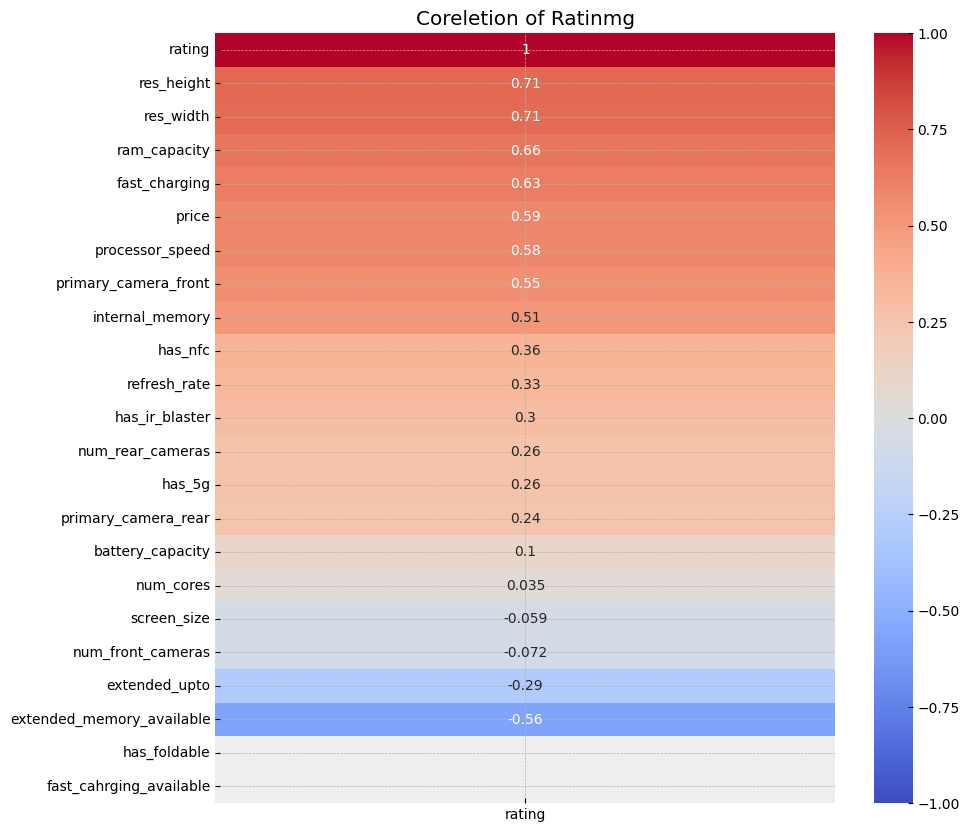

In [45]:
cor_target=filtered_df.corr(numeric_only=True)[['rating']]


cor_target=cor_target.sort_values(by='rating',ascending=False)

plt.figure(figsize=(10,10))
sns.heatmap(cor_target,annot=True,cmap='coolwarm',vmin=-1,vmax=1)
plt.title('Coreletion of Ratinmg')
plt.show()

- This plot shows the rating is based on the all columns as you think how they give the rating on the specs so it is totaly based on the mostly all features in the dataset.

##  SO lets fill the mkissing values using the KNNImputer

In [46]:
x_df=df.select_dtypes(include=['int','float']).drop(columns='price')

In [47]:
from sklearn.impute import KNNImputer

In [48]:
imputer=KNNImputer(n_neighbors=4)

In [49]:
x_df_values=imputer.fit_transform(x_df)

In [50]:
x_df=pd.DataFrame(x_df_values,columns=x_df.columns)

In [51]:
x_df['price']=df['price']

In [52]:
a=x_df.corr()[['price','rating']].reset_index()

In [53]:
b=df.corr(numeric_only=True)[['price','rating']].reset_index()

In [54]:
a.merge(b,on='index')

,index,price_x,rating_x,price_y,rating_y
0,rating,0.495455,1.000000,0.603113,1.000000
1,num_cores,-0.097308,0.030290,-0.097308,0.032661
2,processor_speed,0.723943,0.647098,0.806869,0.591823
3,ram_capacity,0.611133,0.722138,0.611133,0.661298
4,internal_memory,0.429041,0.610311,0.429041,0.554297
5,fast_cahrging_available,0.123627,0.069296,0.123627,NaN
6,battery_capacity,-0.120459,0.160481,-0.120459,0.099826
7,fast_charging,0.291547,0.674281,0.344838,0.638008
8,refresh_rate,0.159493,0.429060,0.159591,0.314368
9,extended_memory_available,-0.519444,-0.626659,-0.519444,-0.560926


In [55]:
filtered_df['ppi']=(np.sqrt(filtered_df['res_width'] ** 2 + filtered_df['res_height'] ** 2)/ filtered_df['screen_size']).round(1)

/tmp/ipykernel_960/412346081.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [56]:
filtered_df['value_score']=(filtered_df['rating'] / (filtered_df['price'] / 10000)
  ).round(2)

/tmp/ipykernel_960/1783626467.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [57]:
filtered_df.isnull().sum()

,0
name,0
brand_name,0
price,0
rating,268
has_5g,0
has_ir_blaster,0
has_nfc,0
has_foldable,0
num_cores,0
processor_speed,53


In [58]:
print(
    filtered_df.groupby('extended_memory_available', dropna=False)[
        'extended_upto'
    ].apply(lambda s: s.isnull().sum())
)
print(filtered_df['extended_upto'].value_counts(dropna=False))

extended_memory_available
0    342
1     67
Name: extended_upto, dtype: int64
extended_upto
NaN       409
1024.0    209
2048.0    105
1.0        55
512.0      17
256.0      15
1536.0      7
128.0       2
Name: count, dtype: int64


In [59]:
filtered_df.loc[
    filtered_df['extended_memory_available'] == 0, 'extended_upto'
] = 0
filtered_df['extended_upto'] = filtered_df['extended_upto'].fillna(
    filtered_df.loc[
        filtered_df['extended_memory_available'] == 1, 'extended_upto'
    ].median()
)

print(filtered_df['extended_upto'].isnull().sum())

0


/tmp/ipykernel_960/1277203147.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



 I filled the values manually becausedoimg KNNImputer blindly can cause the affect on the fast charging and the extended_upto so i check where are extended_memory_available == 0 means there is no having extended memory so i fill it with the 0

 And the second thing is where the extended_memory_available == 1 there i filled with the median of that feature.

In [60]:
print(
    filtered_df.groupby('fast_cahrging_available', dropna=False)[
        'fast_charging'
    ].apply(lambda s: s.isnull().sum())
)

print(
    filtered_df[filtered_df['fast_charging'].isnull()][
        ['brand_name', 'name', 'price', 'fast_cahrging_available']
    ].head(10)
)

fast_cahrging_available
1    56
Name: fast_charging, dtype: int64
    brand_name                     name     price  fast_cahrging_available
20       apple          Apple iPhone 17   86999.0                        1
40       apple          Apple iPhone 17   86999.0                        1
74       apple      Apple iPhone 17 Pro  130490.0                        1
81       apple          Apple iPhone 16   76999.0                        1
99       apple  Apple iPhone 18 Pro Max  179900.0                        1
139      apple  Apple iPhone 17 Pro Max  145990.0                        1
156      apple   Apple iPhone Duo (2TB)  449900.0                        1
165      apple      Apple iPhone 18 Pro  164900.0                        1
199      apple          Apple iPhone 15   67999.0                        1
200        ai+         Ai+ Nova 2 Ultra   20999.0                        1


In [61]:
filtered_df.loc[
    filtered_df['fast_cahrging_available'] == 0, 'fast_charging'
] = 0

filtered_df['fast_charging'] = filtered_df['fast_charging'].fillna(
    filtered_df.groupby('brand_name')['fast_charging'].transform('median'))

filtered_df['fast_charging'] = filtered_df['fast_charging'].fillna(
    filtered_df['fast_charging'].median())

print(filtered_df['fast_charging'].isnull().sum())

0


/tmp/ipykernel_960/1290407279.py:5: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_960/1290407279.py:8: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



- I done here same work which brand supports fast charging that i safely filled with that particular brand.

- If that brand not support the fast charging like apple so for that i given the second fillna(with median())

In [62]:
print(
    filtered_df[filtered_df['processor_speed'].isnull()][
        ['brand_name', 'processor_brand', 'num_cores', 'price']
    ].value_counts()
)

brand_name  processor_brand  num_cores  price   
apple       bionic           6          86999.0     2
realme      snapdragon       8          30999.0     2
apple       bionic           6          71999.0     1
                                        111999.0    1
                                        119900.0    1
                                        130490.0    1
                                        139900.0    1
                                        145990.0    1
                                        154900.0    1
                                        169900.0    1
                                        174900.0    1
                                        185990.0    1
                                        229900.0    1
                                        299900.0    1
                                        324900.0    1
                                        374900.0    1
                                        449900.0    1
google      tensor           8   

In [63]:
filtered_df['processor_speed'] = filtered_df['processor_speed'].fillna(
    filtered_df.groupby(['processor_brand', 'num_cores'])[
        'processor_speed'
    ].transform('median')
)

filtered_df['processor_speed'] = filtered_df['processor_speed'].fillna(
    filtered_df.groupby('processor_brand')['processor_speed'].transform(
        'median'
    )
)

filtered_df['processor_speed'] = filtered_df['processor_speed'].fillna(
    filtered_df['processor_speed'].median()
)

print(filtered_df['processor_speed'].isnull().sum())

0


/tmp/ipykernel_960/1550594456.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_960/1550594456.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/tmp/ipykernel_960/1550594456.py:13: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [64]:
filtered_df.processor_speed.isna().sum()

np.int64(0)

- That is called hierarchical (or cascading) imputation—it works like a safety net that goes from most specific to most general so you never lose accuracy and never leave a NaN behind.

- level 1 is for smartphones like have the unique clcock speed that runs diffrent than the other processor speed like bionic and exynos

- level 2  is like some brand realeased the rare chip like 4 core unisoc that they dont usualy but what if so for that values we use this.

- level 3 in this the brand that dont have the processor speed for that we have gievn the entire column median.

## Lets now use the KNNImputer again

## We are using the standard scaler because the we have to scale the data before filling the nan values with knn
- Because price goes upto 450000 while processor speed is 2.0 to 3.5 something so without scaling price alone controls the distance calculation scaling puts all columns on the same 0 mean 1 std and scaler.inverse_transform() converts the values to the normal.

In [65]:
from sklearn.preprocessing import StandardScaler

In [66]:
knn_features = [
    'rating',
    'price',
    'processor_speed',
    'ram_capacity',
    'internal_memory',
    'fast_charging',
    'refresh_rate',
    'primary_camera_front',
    'ppi',
]

## We are getting ol=nly this much fetures for the filling the na values as we fill some with manualy.

In [67]:
scaler=StandardScaler()
scaled_data=scaler.fit_transform(filtered_df[knn_features])

In [68]:
imputer=KNNImputer(n_neighbors=5,weights='distance')

In [69]:
imputed_scaled=imputer.fit_transform(scaled_data)

In [70]:
filtered_df[knn_features]=scaler.inverse_transform(imputed_scaled)

/tmp/ipykernel_960/1786857234.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [71]:
filtered_df['rating']=filtered_df['rating'].round(1)

/tmp/ipykernel_960/3069698588.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [72]:
filtered_df['value_score']=(filtered_df.rating / (filtered_df.price / 10000)).round(2)

/tmp/ipykernel_960/520824063.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [73]:
filtered_df.isnull().sum()

,0
name,0
brand_name,0
price,0
rating,0
has_5g,0
has_ir_blaster,0
has_nfc,0
has_foldable,0
num_cores,0
processor_speed,0


- ## AS these all EDA is done then we can now apply the one hot encoding to the categorical col and then feature selection for  the model after that model creation.

- ## We can use the get dummies also but that is more form columns and not that much advanced than the onehotEncpoding

- ## Doing OneHotEncoding() for the ML prediction thos is the final doing in this EDA and done **Manual domain based feature selection** in this if anyone done this further he have to do the advance feture selection using the models (**Random Forest and XGBoost**)

- ##  naturally ignore weak or redundant one-hot columns, and Ridge Regression uses L2 regularization to shrink weak coefficients automatically.

In [79]:
cat_cols=filtered_df.select_dtypes(include=['object']).drop(columns='name')

In [81]:
for col in cat_cols:
  print(f'\n{col}({filtered_df[col].nunique} unique):')
  print(filtered_df[col].value_counts())


brand_name(<bound method IndexOpsMixin.nunique of 0          oppo
1       samsung
2          oppo
3      motorola
4          vivo
         ...   
871    motorola
872      xiaomi
873      xiaomi
874      realme
875       apple
Name: brand_name, Length: 819, dtype: object> unique):
brand_name
samsung     143
realme      123
oppo         98
vivo         73
xiaomi       69
poco         59
motorola     58
oneplus      38
apple        35
iqoo         24
google       19
nothing      17
ai+          17
infinix      16
tecno        15
lava         15
Name: count, dtype: int64

processor_brand(<bound method IndexOpsMixin.nunique of 0       dimensity
1      snapdragon
2       dimensity
3      snapdragon
4      snapdragon
          ...    
871    snapdragon
872         helio
873    snapdragon
874         other
875        bionic
Name: processor_brand, Length: 819, dtype: object> unique):
processor_brand
dimensity     333
snapdragon    268
exynos         63
unisoc         58
helio          42
bioni

In [87]:
df_encoded=pd.get_dummies(filtered_df,columns=['brand_name','processor_brand','os'],drop_first=True,dtype=int)

In [110]:
df.select_dtypes(include=['bool']).columns

Index(['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable'], dtype='object')

In [114]:
df_encoded[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']]=df_encoded[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']].astype(int)

In [115]:
print('Shape before:', filtered_df.shape)
print('Shape after:', df_encoded.shape)

Shape before: (819, 29)
Shape after: (819, 49)


In [116]:
df_encoded.head()

,name,price,rating,has_5g,has_ir_blaster,has_nfc,has_foldable,num_cores,processor_speed,ram_capacity,internal_memory,fast_cahrging_available,battery_capacity,fast_charging,refresh_rate,extended_memory_available,extended_upto,screen_size,res_width,res_height,num_rear_cameras,num_front_cameras,primary_camera_rear,primary_camera_front,ppi,value_score,brand_name_apple,brand_name_google,brand_name_infinix,brand_name_iqoo,brand_name_lava,brand_name_motorola,brand_name_nothing,brand_name_oneplus,brand_name_oppo,brand_name_poco,brand_name_realme,brand_name_samsung,brand_name_tecno,brand_name_vivo,brand_name_xiaomi,processor_brand_dimensity,processor_brand_exynos,processor_brand_helio,processor_brand_other,processor_brand_snapdragon,processor_brand_tensor,processor_brand_unisoc,os_ios
0,OPPO F35 Pro,34483.0,80.0,0,0,0,0,8,2.50,8.0,256.0,1,8000.0,80.0,144.0,0,0.0,6.78,1272.0,2772.0,1,1,50.0,50.0,449.8,23.20,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
1,Samsung Galaxy S25 Ultra,94999.0,77.1,1,0,1,0,8,4.47,12.0,256.0,1,5000.0,45.0,120.0,0,0.0,6.90,1440.0,3120.0,4,1,200.0,12.0,498.0,8.12,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
2,OPPO K14 Plus,25999.0,75.0,1,1,0,0,8,2.50,6.0,128.0,1,8000.0,45.0,144.0,1,1024.0,6.78,1272.0,2772.0,3,1,50.0,16.0,449.8,28.85,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0
3,Motorola Edge 70 Fusion,29750.0,70.0,1,0,1,0,8,2.70,8.0,128.0,1,7000.0,68.0,144.0,0,0.0,6.80,1272.0,2772.0,3,1,50.0,32.0,448.5,23.53,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,Vivo V80 5G,62999.0,75.4,1,1,1,0,8,2.80,8.0,128.0,1,7200.0,90.0,144.0,0,0.0,6.59,1260.0,2750.0,3,1,50.0,50.0,459.0,11.97,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0


In [121]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split

In [119]:
ohe=OneHotEncoder(drop='first',handle_unknown='ignore',sparse_output=False,dtype=int)

In [122]:
drop_cols = [
    'name',
    'price',
    'value_score',
    'res_width',
    'res_height',
    'screen_size',
    'num_front_cameras',
]

In [127]:
X=filtered_df.drop(columns=drop_cols)

In [125]:
y=np.log1p(filtered_df.price)

In [128]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [131]:
cat_cols = ['brand_name', 'processor_brand', 'os']

X_train[cat_cols] = X_train[cat_cols].fillna('Unknown').astype(str)
X_test[cat_cols] = X_test[cat_cols].fillna('Unknown').astype(str)

In [132]:
train_cat=pd.DataFrame(
    ohe.fit_transform(X_train[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=X_train.index,
).astype(int)

In [133]:
test_cat=pd.DataFrame(
    ohe.transform(X_test[cat_cols]),
    columns=ohe.get_feature_names_out(cat_cols),
    index=X_test.index,
).astype(int)

In [134]:
X_train_final = pd.concat([X_train.drop(columns=cat_cols), train_cat], axis=1)
X_test_final = pd.concat([X_test.drop(columns=cat_cols), test_cat], axis=1)

In [137]:
print('X_train_final:',X_train_final.shape)
print('X_test_final:',X_test_final.shape)


X_train_final: (655, 42)
X_test_final: (164, 42)


In [142]:
X_train_final[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']]=X_train_final[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']].astype(int)

In [144]:
X_test_final[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']]=X_test_final[['has_5g', 'has_ir_blaster', 'has_nfc', 'has_foldable']].astype(int)